# Proyecto 1
## Reporte de resultados sobre la base de datos Work at olist

### Integrantes
- Laura Berenice Badillo Santos: berenicebadillo10@ciencias.unam.mx
- Eduardo Sánchez Benítez: eduardo_sb@ciencias.unam.mx
- Juan Alberto Jaimes Romero: yoselerratil@gmail.com
- Juan Manuel Sóstenes Sánchez: juansossan@ciencias.unam.mx
- Angel Noriega Cabrera: angelnoriega@ciencias.unam.mx


## 1. Dependencias

Librerías usadas para leer las tablas, calcular los resúmenes y dibujar las gráficas.
`olist_tools` se importa desde `Python/olist_tools.py` en la obtención de datos, cuando ya se conoce la carpeta del proyecto.


In [1]:
from pathlib import Path
import sys
from itertools import combinations

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch


## 2. Configuraciones

Colores, estilo de las figuras y el mínimo de vendedores para comparar estados.


In [2]:
plt.style.use("dark_background")
COL = {
    "azul": "#5a6af5",
    "rosa": "#ed78db",
    "naranja": "#ffa657",
    "rojo": "#ff8077",
    "verde": "#86e092",
}
EXPORTAR = False
MIN_VENDEDORES = 20

def mostrar(fig, nombre):
    fig.tight_layout()
    if EXPORTAR:
        FIGDIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGDIR / f"{nombre}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 3. Obtención de datos

Los datos provienen del **Brazilian E-Commerce Public Dataset by Olist**, publicado por la empresa Olist (repositorio `work-at-olist-data` y Kaggle).
Olist es una plataforma brasileña que conecta a pequeños y medianos comercios con los grandes *marketplaces* de Brasil: el vendedor publica sus productos a través de Olist y la logística de envío se hace con socios de Olist.

- Son **datos comerciales reales** de aproximadamente 100 mil pedidos realizados entre **2016 y 2018**.
- La base está dividida en varias tablas relacionadas (clientes, pedidos, artículos, pagos, reseñas, productos, vendedores y geolocalización) que se unen por llaves como `order_id`, `product_id` y `seller_id`.
- Los montos están en **reales brasileños (BRL)**.

Esta libreta usa `orders`, `order_items` y `sellers`. Los CSV están en `work-at-olist-data/datasets`, junto a la carpeta del equipo.


In [3]:
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "Python" / "olist_tools.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "No encuentro Python/olist_tools.py. "
        "Abre la carpeta del equipo y selecciona su kernel."
    )
PYTHON_DIR = ROOT / "Python"
if str(PYTHON_DIR) not in sys.path:
    sys.path.insert(0, str(PYTHON_DIR))
from olist_tools import (read_tables, build_order_level, build_item_level,
                        table_inventory, missing_profile, safe_minmax, safe_zscore)

DATA_ROOT = next((p for p in (ROOT, *ROOT.parents)
                  if (p / "work-at-olist-data" / "datasets").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "No encuentro work-at-olist-data/datasets junto a la carpeta del equipo."
    )
TABLAS, ORIGEN = read_tables(DATA_ROOT)
DATA_DIR = DATA_ROOT / "work-at-olist-data" / "datasets"
FIGDIR = ROOT / "figures"
print("ORIGEN:", ORIGEN)
print("Directorio raíz:", ROOT)
print("Directorio de datos:", DATA_DIR)
print("Módulo:", __import__("olist_tools").__file__)


ORIGEN: CSV reales suministrados: work-at-olist-data/datasets
Directorio raíz: /home/alberto/projects/DMEMCD_2026_equipo_15
Directorio de datos: /home/alberto/projects/work-at-olist-data/datasets
Módulo: /home/alberto/projects/DMEMCD_2026_equipo_15/Python/olist_tools.py


## 4. Cargado de datos

Se leen las tres tablas en bruto. `items_raw` y `sellers_raw` conservan los tipos con los que llegan del CSV; las correcciones quedan en la limpieza y en las transformaciones.


In [4]:
orders = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
    ],
)
items_raw = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
sellers_raw = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")

print("Origen:", ORIGEN, "| pedidos", len(orders), "| ítems", len(items_raw), "| vendedores", len(sellers_raw))
for nombre, df in [("orders", orders), ("order_items", items_raw), ("sellers", sellers_raw)]:
    print(f"\n{nombre}: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    display(df.head())
    print(df.dtypes.to_string())


Origen: CSV reales suministrados: work-at-olist-data/datasets | pedidos 99441 | ítems 112650 | vendedores 3095

orders: 99,441 filas x 8 columnas


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date               str

order_items: 112,650 filas x 7 columnas


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64

sellers: 3,095 filas x 4 columnas


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str


### Variables

**orders** (unidad: un pedido). En esta libreta se usa la fecha de compra para revisar plazos de envío.

| Variable | Descripción | Tipo |
|---|---|---|
| order_id | Identificador del pedido | Identificador |
| order_purchase_timestamp | Fecha y hora de la compra | Fecha |

**order_items** (unidad: un artículo dentro de un pedido)

| Variable | Descripción | Tipo |
|---|---|---|
| order_id | Identificador del pedido | Identificador |
| order_item_id | Número consecutivo del artículo dentro del pedido | Numérica discreta |
| product_id | Identificador del producto | Identificador |
| seller_id | Identificador del vendedor | Identificador |
| shipping_limit_date | Fecha límite para entregar el artículo | Fecha |
| price | Precio del artículo (BRL) | Numérica continua |
| freight_value | Costo de envío del artículo (BRL) | Numérica continua |

**sellers** (unidad: un vendedor)

| Variable | Descripción | Tipo |
|---|---|---|
| seller_id | Identificador del vendedor | Identificador |
| seller_zip_code_prefix | Primeros 5 dígitos del código postal | Categórica |
| seller_city | Ciudad del vendedor | Categórica nominal |
| seller_state | Estado del vendedor | Categórica nominal |


## 5. Limpieza de datos

Primero se revisan nulos, llaves, el código postal y los valores extremos. Las correcciones que sí se aplican están al final de cada revisión. Los atípicos de precio y flete, y los fletes en cero, se conservan.


In [5]:
# Valores faltantes
tablas = {
    "order_items": items_raw,
    "sellers": sellers_raw,
    "orders (fecha de compra)": orders[["order_purchase_timestamp"]],
}
partes = []
for nombre, df in tablas.items():
    tabla = pd.DataFrame({
        "nulos": df.isna().sum(),
        "% del total": (df.isna().mean() * 100).round(2),
    })
    tabla.insert(0, "tabla", nombre)
    partes.append(tabla)

nulos = pd.concat(partes)
display(nulos)
print("Total de valores nulos:", nulos["nulos"].sum())


,tabla,nulos,% del total
order_id,order_items,0,0.0
order_item_id,order_items,0,0.0
product_id,order_items,0,0.0
seller_id,order_items,0,0.0
shipping_limit_date,order_items,0,0.0
price,order_items,0,0.0
freight_value,order_items,0,0.0
seller_id,sellers,0,0.0
seller_zip_code_prefix,sellers,0,0.0
seller_city,sellers,0,0.0


Total de valores nulos: 0


In [6]:
# Registros duplicados y consistencia de la llave seller_id
dup_items = items_raw.duplicated(subset=["order_id", "order_item_id"]).sum()
dup_sellers = sellers_raw["seller_id"].duplicated().sum()
ids_items = set(items_raw["seller_id"])
ids_sellers = set(sellers_raw["seller_id"])

print(f"Artículos duplicados (mismo order_id y order_item_id): {dup_items}")
print(f"Vendedores duplicados en sellers: {dup_sellers}")
print(f"Vendedores en order_items: {len(ids_items):,} | en sellers: {len(ids_sellers):,}")
print(f"Vendedores de order_items que no están en sellers: {len(ids_items - ids_sellers)}")
print(f"Vendedores registrados sin ventas: {len(ids_sellers - ids_items)}")


Artículos duplicados (mismo order_id y order_item_id): 0
Vendedores duplicados en sellers: 0
Vendedores en order_items: 3,095 | en sellers: 3,095
Vendedores de order_items que no están en sellers: 0
Vendedores registrados sin ventas: 0


Observamos que:

1. En `order_items` cada fila es única por la combinación `order_id` + `order_item_id`.
2. En `sellers` cada fila es un vendedor distinto.
3. Todos los `seller_id` de `order_items` existen en `sellers`.


In [7]:
# El CEP brasileño tiene 5 dígitos. Al leerlo como entero se pierde el cero inicial.
digitos_cep = sellers_raw["seller_zip_code_prefix"].astype(str).str.len()
print("Tipo de seller_zip_code_prefix:", sellers_raw["seller_zip_code_prefix"].dtype)
print("Número de dígitos del código postal:")
print(digitos_cep.value_counts().sort_index().to_string())
print("\nTipo de shipping_limit_date:", items_raw["shipping_limit_date"].dtype)
print("Ejemplo:", items_raw["shipping_limit_date"].iloc[0])


Tipo de seller_zip_code_prefix: int64
Número de dígitos del código postal:
seller_zip_code_prefix
4    1027
5    2068

Tipo de shipping_limit_date: str
Ejemplo: 2017-09-19 09:45:35


### Código postal como texto de 5 dígitos

- La columna `seller_zip_code_prefix` se analizó como número entero y 1,027 vendedores tienen un código de 4 dígitos. El prefijo del código postal brasileño (CEP) siempre tiene 5 dígitos.
- En la columna se completa con un cero a la izquierda para que sean 5 dígitos.
- Antes de hacer dicha corrección se verifica con una columna independiente del código postal, el estado del vendedor. Si el dígito faltante es un 0 inicial, esos vendedores deben ser de São Paulo, cuyos códigos empiezan con 0.


In [8]:
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv",
                      dtype={"seller_zip_code_prefix": str})
sellers["seller_zip_code_prefix"] = sellers["seller_zip_code_prefix"].str.zfill(5)

cuatro_digitos = digitos_cep == 4
print(f"Vendedores con código de 4 dígitos: {cuatro_digitos.sum():,}")
print("Su estado según seller_state:")
print(sellers_raw.loc[cuatro_digitos, "seller_state"].value_counts().to_string())
print("\nSus ciudades más frecuentes:")
print(sellers_raw.loc[cuatro_digitos, "seller_city"].value_counts().head(5).to_string())

comparacion = (pd.DataFrame({
                    "antes": digitos_cep.value_counts(),
                    "después": sellers["seller_zip_code_prefix"].str.len().value_counts(),
                })
               .fillna(0).astype(int).rename_axis("dígitos del código postal"))
display(comparacion)


Vendedores con código de 4 dígitos: 1,027
Su estado según seller_state:
seller_state
SP    1027

Sus ciudades más frecuentes:
seller_city
sao paulo                687
guarulhos                 50
santo andre               45
sao bernardo do campo     32
osasco                    32


,antes,después
dígitos del código postal,,
4,1027,0
5,2068,3095


Los 1,027 vendedores con código de 4 dígitos son de SP, de la ciudad de São Paulo y su zona metropolitana, lo que confirma que el dígito faltante es el cero inicial. Después de dicha corrección, todos los códigos tienen 5 dígitos.


In [9]:
# Atípicos por la regla del IQR, sobre la tabla en bruto
for col in ["price", "freight_value"]:
    q1 = items_raw[col].quantile(0.25)
    q3 = items_raw[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    por_abajo = (items_raw[col] < lim_inf).sum()
    por_arriba = (items_raw[col] > lim_sup).sum()
    total = por_abajo + por_arriba
    print(f"{col}: límites [{lim_inf:.2f}, {lim_sup:.2f}] -> {total:,} atípicos "
          f"({total / len(items_raw):.1%}): {por_abajo:,} por abajo y {por_arriba:,} por arriba")

print(f"\nArtículos con precio menor a 5 BRL: {(items_raw['price'] < 5).sum()}")
print(f"Artículos con flete igual a 0: {(items_raw['freight_value'] == 0).sum()}")


price: límites [-102.60, 277.40] -> 8,427 atípicos (7.5%): 0 por abajo y 8,427 por arriba
freight_value: límites [0.98, 33.25] -> 12,180 atípicos (10.8%): 521 por abajo y 11,659 por arriba

Artículos con precio menor a 5 BRL: 117
Artículos con flete igual a 0: 383


### Artículos con flete igual a 0

- 383 artículos (0.3%) tienen un costo de envío de 0 y aparecen como atípicos por abajo según la regla del IQR. Podían ser errores de captura, envíos gratuitos, o casos en que el flete se cargó a otro artículo del mismo pedido.
- Se revisan los pedidos y los vendedores a los que pertenecen.


In [10]:
cero = items_raw[items_raw["freight_value"] == 0]
flete_pedido = items_raw.groupby("order_id")["freight_value"].sum()
pedidos_cero = cero["order_id"].unique()

print(f"Pedidos con algún artículo de flete 0: {len(pedidos_cero)}")
print(f"Pedidos en los que todos los articulos del pedido tiene flete 0: {(flete_pedido.loc[pedidos_cero] == 0).sum()}")
print(f"Vendedores distintos con flete 0: {cero['seller_id'].nunique()}")
print("\nVendedores con más artículos de flete 0:")
print(cero["seller_id"].value_counts().head(5).to_string())


Pedidos con algún artículo de flete 0: 339
Pedidos en los que todos los articulos del pedido tiene flete 0: 338
Vendedores distintos con flete 0: 9

Vendedores con más artículos de flete 0:
seller_id
7d13fca15225358621be4086e1eb0964    158
955fee9216a65b617aa5c0531780ce60     99
1f50f920176fa81dab994f9023523100     56
4869f7a5dfa277a7dca6462dcf3b52b2     56
37be5a7c751166fbc5f8ccba4119e043      9


Los valores corresponden a envíos gratuitos, probablemente por los vendedores, y no a errores. Se conservan sin modificar ni eliminarlos porque subestimaría la existencia de envíos gratis y alteraría el análisis del flete.


### Valores atípicos de precio y flete según la regla del IQR

- El análisis de la regla del IQR marca como atípicos a 8,427 artículos por su precio (7.5%) y a 12,180 por su flete (10.8%).
- Dichos datos son demasiado altos para tratarse de errores de captura. Para saber si deberíamos eliminarlos, se comparan los resultados con y sin ellos.


In [11]:
resultados = []
for col in ["price", "freight_value"]:
    q1 = items_raw[col].quantile(0.25)
    q3 = items_raw[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    todos = items_raw[col]
    sin_atipicos = todos[(todos >= lim_inf) & (todos <= lim_sup)]
    perdida = (1 - sin_atipicos.sum() / todos.sum()) * 100
    resultados.append([col, todos.mean(), sin_atipicos.mean(),
                       todos.median(), sin_atipicos.median(), perdida])

efecto = pd.DataFrame(resultados, columns=[
    "variable", "media (todos)", "media (sin atípicos)",
    "mediana (todos)", "mediana (sin atípicos)",
    "% del total que se perdería",
])
display(efecto.round(2))


,variable,media (todos),media (sin atípicos),mediana (todos),mediana (sin atípicos),% del total que se perdería
0,price,120.65,83.97,74.99,69.00,35.61
1,freight_value,20.03,16.13,16.27,15.62,28.20


Los valores atípicos **se conservan** porque corresponden a productos de mayor valor, artículos voluminosos o envíos a mayor distancia, que forman parte real de los datos.


## 6. Transformaciones

`shipping_limit_date` pasa a fecha. Con los vendedores ya corregidos se arma una fila por artículo, con el estado agrupado y el flete respecto del precio.


In [12]:
items = items_raw.copy()
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

fechas_raras = items[items["shipping_limit_date"] > "2018-12-31"].copy()
fechas_raras["fecha_compra"] = fechas_raras["order_id"].map(
    orders.set_index("order_id")["order_purchase_timestamp"])
fechas_raras["plazo_dias"] = (
    fechas_raras["shipping_limit_date"] - fechas_raras["fecha_compra"]
).dt.days
display(fechas_raras[["order_id", "seller_id", "fecha_compra",
                      "shipping_limit_date", "plazo_dias", "price", "freight_value"]])


,order_id,seller_id,fecha_compra,shipping_limit_date,plazo_dias,price,freight_value
8643,13bdf405f961a6deec817d817f5c6624,7a241947449cc45dbfda4f9d0798d9d0,2017-03-16 02:30:51,2020-02-05 03:30:51,1056,69.99,14.66
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,7a241947449cc45dbfda4f9d0798d9d0,2017-03-14 19:23:22,2020-02-03 20:23:22,1056,75.99,14.70
85729,c2bb89b5c1dd978d507284be78a04cb2,7a241947449cc45dbfda4f9d0798d9d0,2017-05-23 22:28:36,2020-04-09 22:35:08,1052,99.99,61.44
85730,c2bb89b5c1dd978d507284be78a04cb2,7a241947449cc45dbfda4f9d0798d9d0,2017-05-23 22:28:36,2020-04-09 22:35:08,1052,99.99,61.44


In [13]:
articulos_por_pedido = items.groupby("order_id")["order_item_id"].max()
panorama = pd.Series({
    "Artículos vendidos (filas de order_items)": f"{len(items):,}",
    "Pedidos distintos": f"{items['order_id'].nunique():,}",
    "Productos distintos": f"{items['product_id'].nunique():,}",
    "Vendedores con ventas": f"{items['seller_id'].nunique():,}",
    "Pedidos con más de un artículo": f"{(articulos_por_pedido > 1).mean():.1%}",
    "Fecha límite de envío mínima": items["shipping_limit_date"].min().date(),
    "Fecha límite de envío máxima": items["shipping_limit_date"].max().date(),
    "Ventas totales (price, BRL)": f"{items['price'].sum():,.2f}",
    "Fletes totales (freight_value, BRL)": f"{items['freight_value'].sum():,.2f}",
    "Estados con vendedores": sellers["seller_state"].nunique(),
    "Ciudades con vendedores": sellers["seller_city"].nunique(),
}, name="valor")
display(panorama.to_frame())

items_sellers = items.merge(sellers, on="seller_id", how="left", validate="many_to_one")
print("Tabla unida items + sellers:", items_sellers.shape)
display(items_sellers.head())


,valor
Artículos vendidos (filas de order_items),"112,650"
Pedidos distintos,"98,666"
Productos distintos,"32,951"
Vendedores con ventas,"3,095"
Pedidos con más de un artículo,9.9%
Fecha límite de envío mínima,2016-09-19
Fecha límite de envío máxima,2020-04-09
"Ventas totales (price, BRL)","13,591,643.70"
"Fletes totales (freight_value, BRL)","2,256,599.44"
Estados con vendedores,23


Tabla unida items + sellers: (112650, 10)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,27277,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,03471,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,37564,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,14403,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,87900,loanda,PR


In [14]:
vendedores_por_estado = sellers["seller_state"].value_counts()
estados_grandes = vendedores_por_estado[vendedores_por_estado >= MIN_VENDEDORES].index
items_sellers["grupo_estado"] = np.where(
    items_sellers["seller_state"].isin(estados_grandes),
    items_sellers["seller_state"],
    "Otros",
)
items_sellers["flete_sobre_precio"] = items_sellers["freight_value"] / items_sellers["price"]
print("Estados conservados con su nombre:", ", ".join(estados_grandes))
print(items_sellers["grupo_estado"].value_counts().to_string())


Estados conservados con su nombre: SP, PR, MG, SC, RJ, RS, GO, DF, ES
grupo_estado
SP       80342
MG        8827
PR        8671
RJ        4818
SC        4075
RS        2199
Otros     1927
DF         899
GO         520
ES         372


## 7. Análisis exploratorio

**Preguntas:**

1. ¿Cómo se distribuyen el precio y el costo de envío de los artículos? ¿Son simétricos o hay muchos artículos baratos y pocos muy caros?
2. ¿Cuántos artículos vende un vendedor típico? ¿Las ventas se reparten entre muchos vendedores o se concentran en pocos?
3. ¿Cambian el precio y el costo de envío promedio según el estado del vendedor?
4. ¿Cuál es el precio promedio por artículo y por pedido, y cómo varía según el estado del vendedor?

**¿Los datos son adecuados para dicho análisis?**

- `order_items` tiene, a nivel de cada artículo, las dos variables numéricas centrales (`price` y `freight_value`) y el vendedor que lo vendió, lo que permite calcular medidas de tendencia central, dispersión y posición.
- `sellers` aporta la dimensión geográfica (estado y ciudad), que permite **comparar grupos o segmentos** de vendedores.
- La llave `seller_id` une ambas tablas sin pérdida de información (lo verificamos al revisar las llaves).
- Son datos reales de operación con un volumen grande (más de 100 mil artículos), por lo que los resultados son representativos de la actividad del marketplace en el periodo 2016–2018.

**¿Hay limitaciones con la información?** Sí, porque los datos solo cubren un periodo y solo a los vendedores de Olist.


### Pregunta 1. ¿Cómo se distribuyen el precio y el costo de envío de los artículos? ¿Son simétricos o hay muchos artículos baratos y pocos muy caros?


In [15]:
vars_num = ["price", "freight_value"]
datos = items_sellers[vars_num]

resumen = datos.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
resumen["moda"] = datos.mode().iloc[0]
resumen["rango"] = resumen["max"] - resumen["min"]
resumen["IQR"] = resumen["75%"] - resumen["25%"]
resumen["coef_variacion"] = resumen["std"] / resumen["mean"]
resumen["asimetria"] = datos.skew()
display(resumen.round(2))


,count,mean,std,min,5%,25%,50%,75%,95%,max,moda,rango,IQR,coef_variacion,asimetria
price,112650.0,120.65,183.63,0.85,17.00,39.90,74.99,134.90,349.90,6735.00,59.9,6734.15,95.00,1.52,7.92
freight_value,112650.0,20.03,16.02,0.00,7.78,13.08,16.27,21.15,45.23,409.68,15.1,409.68,8.07,0.80,5.79


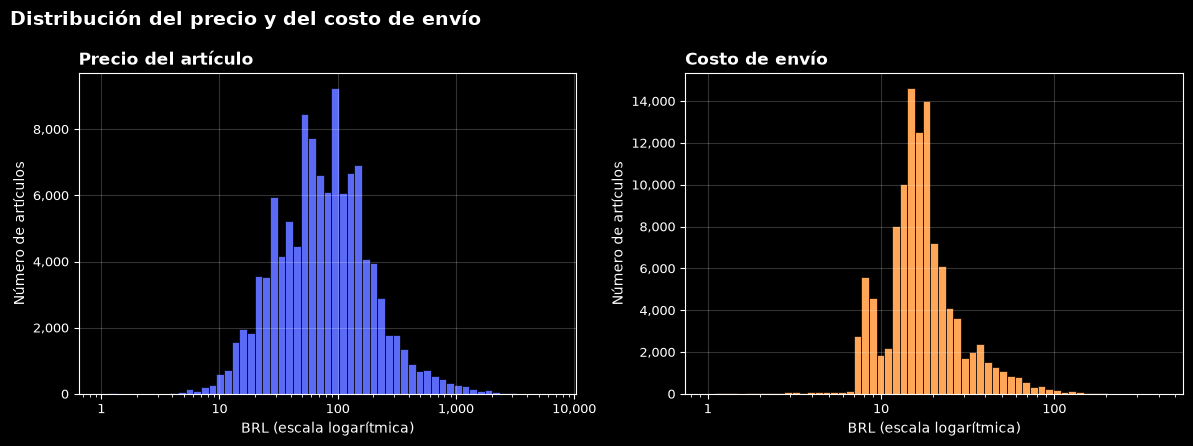

In [16]:
variables = [("price", "Precio del artículo", COL["azul"]),
             ("freight_value", "Costo de envío", COL["naranja"])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (col, titulo, color) in zip(axes, variables):
    vista = items_sellers.loc[items_sellers[col] >= 1, col]  # la escala log no admite ceros
    bins = np.logspace(0, np.log10(vista.max()), 60)
    ax.hist(vista, bins=bins, color=color, edgecolor="black", linewidth=0.5)
    ax.set_xscale("log")
    ax.set_title(titulo, fontsize=12, fontweight="bold", loc="left")
    ax.set_xlabel("BRL (escala logarítmica)", fontsize=10)
    ax.set_ylabel("Número de artículos", fontsize=10)
    ax.tick_params(labelsize=9)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(alpha=0.2)

fig.suptitle("Distribución del precio y del costo de envío", fontsize=14, fontweight="bold",
             x=0.01, ha="left")
mostrar(fig, "3_1a_histogramas")


### Pregunta 2. ¿Cuántos artículos vende un vendedor normalmente? ¿Las ventas se concentran en un grupo especifico de vendedores?


In [17]:
por_vendedor = (items_sellers.groupby("seller_id")
                .agg(articulos=("order_item_id", "size"),
                     pedidos=("order_id", "nunique"),
                     ventas_brl=("price", "sum"),
                     estado=("seller_state", "first")))

cols = ["articulos", "pedidos", "ventas_brl"]
res_v = por_vendedor[cols].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
res_v["asimetria"] = por_vendedor[cols].skew()
display(res_v.round(2))


,count,mean,std,min,25%,50%,75%,90%,99%,max,asimetria
articulos,3095.0,36.40,119.19,1.0,2.00,8.00,24.00,80.00,431.24,2033.00,9.79
pedidos,3095.0,32.31,105.14,1.0,2.00,6.00,21.50,69.60,402.24,1854.00,9.64
ventas_brl,3095.0,4391.48,13922.00,3.5,208.85,821.48,3280.83,9525.32,55108.72,229472.63,9.05


In [18]:
orden = por_vendedor.sort_values("ventas_brl", ascending=False)
participacion = orden["ventas_brl"].cumsum() / orden["ventas_brl"].sum()
n = len(orden)

for pct in [0.01, 0.10, 0.20]:
    k = int(round(n * pct))
    print(f"El {pct:.0%} de los vendedores ({k:,}) genera el "
          f"{participacion.iloc[k - 1]:.1%} de las ventas")

for meta in [0.5, 0.8]:
    k = (participacion < meta).sum() + 1
    print(f"{k:,} vendedores ({k / n:.1%}) generan el {meta:.0%} de las ventas")


El 1% de los vendedores (31) genera el 26.1% de las ventas
El 10% de los vendedores (310) genera el 67.6% de las ventas
El 20% de los vendedores (619) genera el 82.7% de las ventas
130 vendedores (4.2%) generan el 50% de las ventas
544 vendedores (17.6%) generan el 80% de las ventas


In [19]:
cortes = [0, 1, 5, 20, 100, np.inf]
etiquetas = ["1 artículo", "2 a 5", "6 a 20", "21 a 100", "más de 100"]
por_vendedor["segmento"] = pd.cut(por_vendedor["articulos"], bins=cortes, labels=etiquetas)

seg = (por_vendedor.groupby("segmento", observed=True)
       .agg(vendedores=("articulos", "size"), ventas_brl=("ventas_brl", "sum")))
seg["%_vendedores"] = seg["vendedores"] / seg["vendedores"].sum() * 100
seg["%_ventas"] = seg["ventas_brl"] / seg["ventas_brl"].sum() * 100
display(seg.round(1))


,vendedores,ventas_brl,%_vendedores,%_ventas
segmento,,,,
1 artículo,509,115167.5,16.4,0.8
2 a 5,834,527065.8,26.9,3.9
6 a 20,882,1698275.4,28.5,12.5
21 a 100,634,4024854.2,20.5,29.6
más de 100,236,7226280.7,7.6,53.2


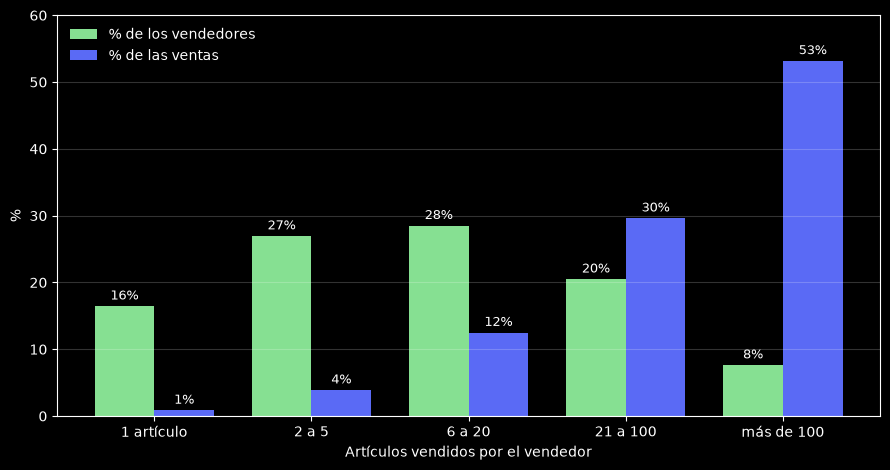

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.8))

pos = np.arange(len(seg))
ancho = 0.38
ax.bar(pos - ancho / 2, seg["%_vendedores"], ancho, color=COL["verde"], label="% de los vendedores")
ax.bar(pos + ancho / 2, seg["%_ventas"], ancho, color=COL["azul"], label="% de las ventas")

for i in range(len(seg)):
    valor_vendedores = seg["%_vendedores"].iloc[i]
    valor_ventas = seg["%_ventas"].iloc[i]
    ax.text(i - ancho / 2, valor_vendedores + 1, f"{valor_vendedores:.0f}%", ha="center", fontsize=9)
    ax.text(i + ancho / 2, valor_ventas + 1, f"{valor_ventas:.0f}%", ha="center", fontsize=9)

ax.set_xticks(pos, seg.index)
ax.set_ylim(0, 60)
ax.set_xlabel("Artículos vendidos por el vendedor", fontsize=10)
ax.set_ylabel("%", fontsize=10)
ax.legend(loc="upper left", frameon=False)
ax.grid(axis="y", alpha=0.2)

mostrar(fig, "3_2_segmentos_vendedores")


### Pregunta 3. ¿Cambia el precio y el costo de envío promedio de acuerdo con el estado del vendedor?


In [21]:
por_estado = (items_sellers.groupby("grupo_estado")
              .agg(vendedores=("seller_id", "nunique"), articulos=("price", "size"),
                   precio_mediana=("price", "median"), precio_media=("price", "mean"),
                   flete_mediana=("freight_value", "median"), flete_media=("freight_value", "mean"),
                   flete_sobre_precio_mediana=("flete_sobre_precio", "median"))
              .sort_values("flete_mediana"))
display(por_estado.round(2))


,vendedores,articulos,precio_mediana,precio_media,flete_mediana,flete_media,flete_sobre_precio_mediana
grupo_estado,,,,,,,
SP,1849,80342,69.0,108.95,15.38,18.50,0.24
RJ,171,4818,105.0,175.17,16.70,19.47,0.16
PR,349,8671,98.9,145.53,17.78,22.72,0.20
DF,30,899,69.9,108.73,17.80,20.57,0.26
MG,244,8827,84.9,114.60,18.06,24.16,0.26
SC,190,4075,89.0,155.20,18.78,26.15,0.24
RS,129,2199,105.0,172.15,19.33,26.08,0.21
GO,40,520,89.9,127.69,21.12,24.16,0.25
Otros,70,1927,149.9,258.43,25.54,30.60,0.17


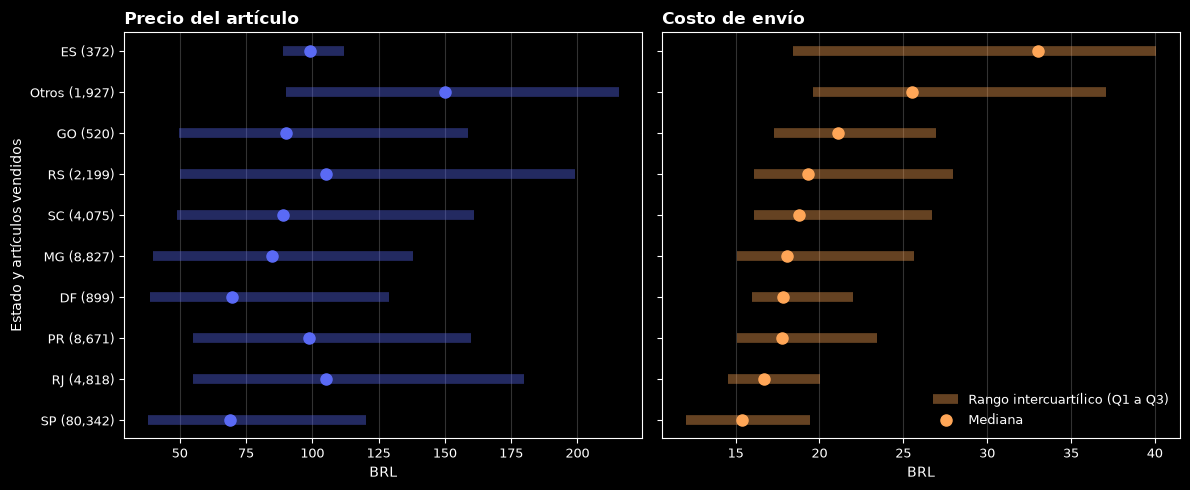

In [22]:
variables = [("price", "Precio del artículo", COL["azul"]),
             ("freight_value", "Costo de envío", COL["naranja"])]

cuartiles = (items_sellers.groupby("grupo_estado")[["price", "freight_value"]]
             .quantile([0.25, 0.5, 0.75]).unstack())

orden_estados = por_estado.index
etiquetas_estado = [f"{estado} ({por_estado.loc[estado, 'articulos']:,})" for estado in orden_estados]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (col, titulo, color) in zip(axes, variables):
    q = cuartiles[col].loc[orden_estados]
    y = np.arange(len(q))
    ax.hlines(y, q[0.25], q[0.75], color=color, lw=7, alpha=0.4, label="Rango intercuartílico (Q1 a Q3)")
    ax.plot(q[0.5], y, "o", color=color, markersize=8, label="Mediana")
    ax.set_title(titulo, fontsize=12, fontweight="bold", loc="left")
    ax.set_xlabel("BRL", fontsize=10)
    ax.tick_params(labelsize=9)
    ax.grid(axis="x", alpha=0.2)

axes[0].set_yticks(np.arange(len(orden_estados)), etiquetas_estado)
axes[0].set_ylabel("Estado y artículos vendidos", fontsize=10)
axes[1].legend(loc="lower right", fontsize=9, frameon=False)

mostrar(fig, "3_3_precio_flete_por_estado")


### Pregunta 4. ¿Cuál es el precio promedio por artículo y por pedido, y cómo varía según el estado del vendedor?


In [23]:
pedidos_vendedor = (items_sellers.groupby(["order_id", "seller_id", "grupo_estado"])
                    .agg(articulos=("price", "size"), ticket=("price", "sum"))
                    .reset_index())
pedidos_multivendedor = (items_sellers.groupby("order_id")["seller_id"].nunique() > 1).sum()
print(f"Pedidos con artículos de más de un vendedor: {pedidos_multivendedor:,} "
      f"({pedidos_multivendedor / items_sellers['order_id'].nunique():.1%})")

general = pd.DataFrame({
    "media": [items_sellers["price"].mean(), pedidos_vendedor["ticket"].mean(),
              pedidos_vendedor["articulos"].mean()],
    "mediana": [items_sellers["price"].median(), pedidos_vendedor["ticket"].median(),
                pedidos_vendedor["articulos"].median()],
}, index=["Ticket por artículo (BRL)", "Ticket por pedido (BRL)", "Artículos por pedido"])
display(general.round(2))
print(f"Pedidos con un solo artículo del vendedor: {(pedidos_vendedor['articulos'] == 1).mean():.1%}")

ticket_estado = (pedidos_vendedor.groupby("grupo_estado")
                 .agg(pedidos=("ticket", "size"), ticket_pedido_mediana=("ticket", "median"),
                      ticket_pedido_media=("ticket", "mean"), articulos_por_pedido=("articulos", "mean")))
ticket_estado["ticket_articulo_mediana"] = por_estado["precio_mediana"]
ticket_estado["ticket_articulo_media"] = por_estado["precio_media"]
ticket_estado = ticket_estado.sort_values("ticket_pedido_mediana")
display(ticket_estado.round(2))


Pedidos con artículos de más de un vendedor: 1,278 (1.3%)


,media,mediana
Ticket por artículo (BRL),120.65,74.99
Ticket por pedido (BRL),135.90,84.99
Artículos por pedido,1.13,1.00


Pedidos con un solo artículo del vendedor: 91.1%


,pedidos,ticket_pedido_mediana,ticket_pedido_media,articulos_por_pedido,ticket_articulo_mediana,ticket_articulo_media
grupo_estado,,,,,,
DF,824,75.00,118.63,1.09,69.9,108.73
SP,70950,78.00,123.37,1.13,69.0,108.95
MG,7942,89.99,127.37,1.11,84.9,114.60
GO,463,98.99,143.41,1.12,89.9,127.69
ES,318,99.00,149.97,1.17,99.0,128.20
PR,7717,99.99,163.52,1.12,98.9,145.53
SC,3672,104.00,172.23,1.11,89.0,155.20
RJ,4355,117.70,193.80,1.11,105.0,175.17
RS,1991,119.90,190.14,1.10,105.0,172.15


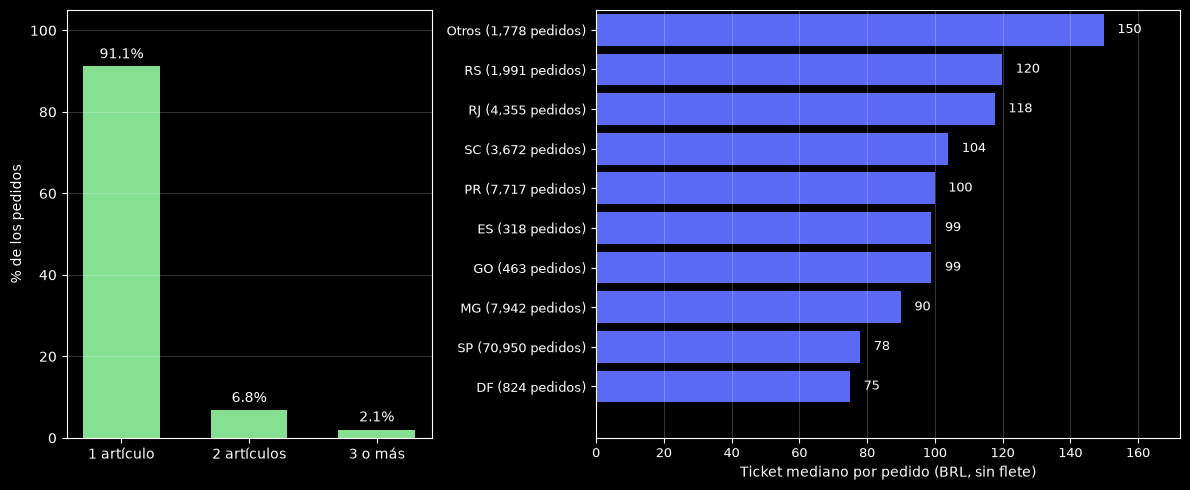

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.6]})

num_articulos = pedidos_vendedor["articulos"].clip(upper=3)
reparto = num_articulos.value_counts(normalize=True).sort_index() * 100
etiquetas = ["1 artículo", "2 artículos", "3 o más"]

ax1.bar(etiquetas, reparto, color=COL["verde"], width=0.6)
for i in range(len(reparto)):
    ax1.text(i, reparto.iloc[i] + 2, f"{reparto.iloc[i]:.1f}%", ha="center", fontsize=10)
ax1.set_ylim(0, 105)
ax1.set_ylabel("% de los pedidos", fontsize=10)
ax1.grid(axis="y", alpha=0.2)

orden = ticket_estado.sort_values("ticket_pedido_mediana")
etiquetas_estado = [f"{estado} ({orden.loc[estado, 'pedidos']:,} pedidos)" for estado in orden.index]

ax2.barh(etiquetas_estado, orden["ticket_pedido_mediana"], color=COL["azul"])
for i in range(len(orden)):
    valor = orden["ticket_pedido_mediana"].iloc[i]
    ax2.text(valor + 4, i, f"{valor:,.0f}", va="center", fontsize=9)

mediana_general = pedidos_vendedor["ticket"].median()
ax2.set_ylim(-1.3, len(orden) - 0.5)
ax2.set_xlim(0, orden["ticket_pedido_mediana"].max() * 1.15)
ax2.set_xlabel("Ticket mediano por pedido (BRL, sin flete)", fontsize=10)
ax2.tick_params(labelsize=9)
ax2.grid(axis="x", alpha=0.2)

mostrar(fig, "3_4_ticket_por_estado")


## 8. Conclusión

El precio y el flete de los artículos son asimétricos: hay muchos productos baratos y una cola de precios altos. Las ventas se concentran en pocos vendedores, y el valor de un pedido depende casi siempre de un solo artículo. El estado del vendedor cambia el flete mediano; el precio mediano cambia menos, salvo en los estados pequeños agrupados en «Otros».

### Precio y costo de envío

La mayoría de los artículos cuesta entre 20 y 200 BRL. La mediana es de 74.99 BRL y la media sube a 120.65 BRL por los pocos artículos con un precio muy caro.

La mayoría de los fletes están entre 13 y 21 BRL, su mediana es de 16.27 BRL, con un grupo más pequeño alrededor de 8 BRL y una cola de fletes caros de más de 100 BRL.

### Concentración de vendedores

Las ventas están concentradas en pocos vendedores. El vendedor usual vendió solo 8 artículos en todo el periodo.

- Los vendedores con **más de 100 artículos** son solo el 8%, pero generan el **53% de las ventas**.
- En el otro lado, los que vendieron **5 artículos o menos** son el **43%** de los vendedores y generan apenas el **5% de las ventas**.

### Precio y flete según el estado del vendedor

- En São Paulo se concentra el 59% de los vendedores y el 71% de los artículos, y tiene el flete mediano más bajo de 15.35 BRL y uno de los precios medianos más bajos (69 BRL).
- Espírito Santo tiene el flete mediano más alto de 32.98 BRL y Bahía el precio mediano más alto, 235.90 BRL. El flete tiende a ser menor en el estado donde se concentran los vendedores.

Se podría intuir que muchos compradores se encuentran cerca del sureste de Brasil y que los envíos son más cortos. Bahía no aparece con su nombre en la tabla: tiene 19 vendedores, por debajo del corte de 20, y queda dentro de «Otros».

### Ticket por artículo y por pedido

- El ticket mediano por artículo es de 74.99 BRL y el ticket mediano por pedido de 84.99 BRL. Esta diferencia se debe a que el 91% de los pedidos solo tiene un artículo de cada vendedor.
- Por estado, Bahía tiene el ticket mediano por pedido más alto, de 283 BRL, mientras que SP y DF tienen los más bajos (75 a 78 BRL). En la tabla agrupada, DF queda en 75 BRL y SP en 78 BRL; Bahía forma parte de «Otros».
- El valor de un pedido depende casi por completo del precio de un solo artículo; casi no hay compras de varios productos al mismo vendedor.
- Podría haber una oportunidad en promociones para agregar más artículos, por ejemplo un descuento o el envío gratis al comprar 2 o 3 productos.
